# PathSnap — 02 Feature Selection
We engineered 8 candidate features per (GPS point, candidate arc) pair. This notebook checks, with evidence, whether each one is useful.

**Data:** train partition only (80 trips) for all selection decisions — same rows the models train on (usable points, every 3rd point). Student-test is used only in step 5 to confirm, never to choose.

In [1]:
import sys, os; sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier
from src.features.candidates import FEATURES
from src.models.train_compare import load_train
%matplotlib inline
sns.set_theme(style='whitegrid'); FIG='../reports/figures'
train = load_train(); X, y, g = train[FEATURES], train.label.values, train.trip.values
print(train.shape, 'positive rate %.3f' % y.mean())
train[FEATURES + ['label']].describe().T.round(2)

(331118, 14) positive rate 0.176


,count,mean,std,min,25%,50%,75%,max
dist_m,331118.0,17.45,13.28,0.00,6.25,14.18,26.66,50.00
dist_rank,331118.0,2.88,2.24,0.00,1.00,3.00,5.00,7.00
dist_minus_min,331118.0,11.98,13.01,0.00,0.00,7.78,20.61,49.93
heading_diff_deg,331118.0,86.92,66.32,0.00,17.04,83.94,159.15,180.00
arc_len_m,331118.0,118.26,236.66,0.11,22.91,52.51,117.90,4671.06
speed_mps,331118.0,12.15,9.78,0.00,4.80,9.71,16.75,109.75
n_candidates,331118.0,6.76,1.95,1.00,6.00,8.00,8.00,8.00
frac_along,331118.0,0.50,0.42,0.00,0.00,0.49,1.00,1.00
label,331118.0,0.18,0.38,0.00,0.00,0.00,0.00,1.00


## 1. How each feature differs between the true arc and wrong arcs

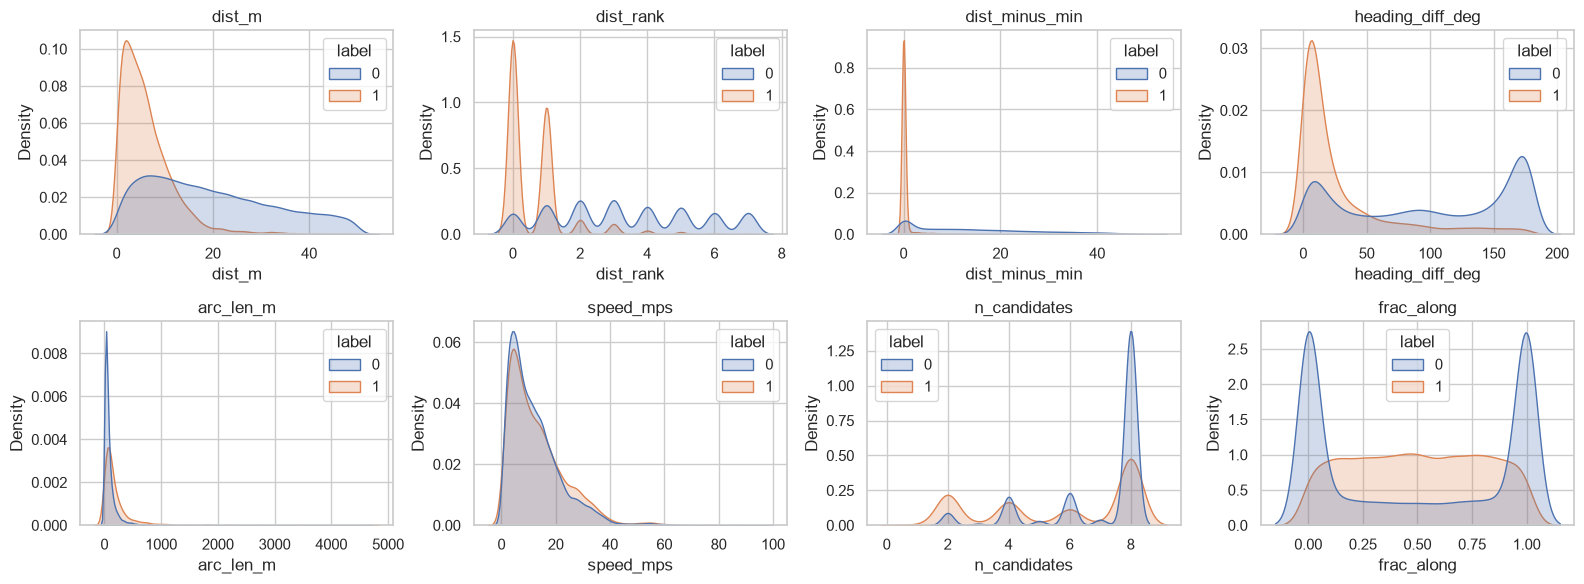

In [2]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for a, f in zip(ax.ravel(), FEATURES):
    sns.kdeplot(data=train.sample(60000, random_state=42), x=f, hue='label', common_norm=False, fill=True, ax=a, warn_singular=False)
    a.set_title(f)
plt.tight_layout(); plt.savefig(f'{FIG}/fs_distributions.png', dpi=110); plt.show()

## 2. Correlation between features (redundancy check)

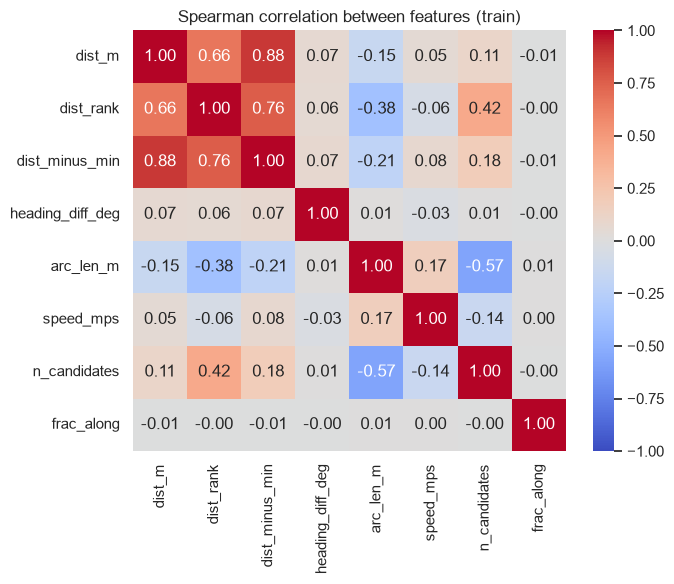

Pairs with |rho| > 0.8: [('dist_m', 'dist_minus_min', np.float64(0.88))]


In [3]:
corr = X.corr(method='spearman')
plt.figure(figsize=(7,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman correlation between features (train)'); plt.tight_layout(); plt.savefig(f'{FIG}/fs_correlation.png', dpi=110); plt.show()
high = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if abs(corr.loc[a, b]) > 0.8]
print('Pairs with |rho| > 0.8:', high)

## 3. Mutual information with the label (model-free relevance)

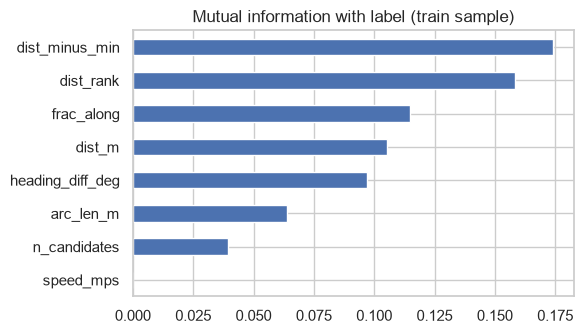

dist_minus_min      0.1741
dist_rank           0.1585
frac_along          0.1147
dist_m              0.1055
heading_diff_deg    0.0971
arc_len_m           0.0639
n_candidates        0.0395
speed_mps           0.0000
dtype: float64

In [4]:
s = train.sample(80000, random_state=42)
mi = pd.Series(mutual_info_classif(s[FEATURES], s.label, random_state=42), index=FEATURES).sort_values()
mi.plot.barh(figsize=(6,3.5), title='Mutual information with label (train sample)'); plt.tight_layout(); plt.savefig(f'{FIG}/fs_mutual_info.png', dpi=110); plt.show()
mi.sort_values(ascending=False).round(4)

## 4. Model-based importance: Random Forest impurity + permutation importance (on held-out trips)

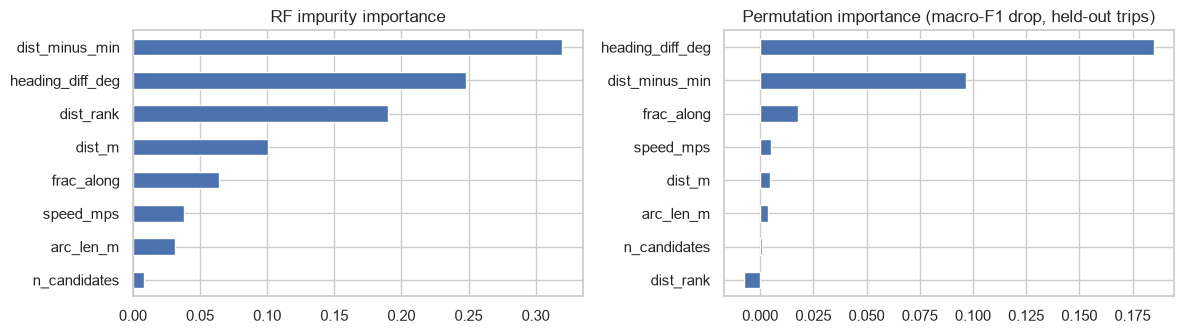

,rf_impurity,permutation_f1_drop
heading_diff_deg,0.2478,0.1849
dist_minus_min,0.3193,0.0965
frac_along,0.0645,0.0176
speed_mps,0.0384,0.0053
dist_m,0.1005,0.0048
arc_len_m,0.0314,0.0035
n_candidates,0.0080,0.0009
dist_rank,0.1901,-0.0074


In [5]:
tr, va = next(GroupKFold(n_splits=5).split(X, y, g))   # one trip-grouped split
rf = RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=42).fit(X.iloc[tr], y[tr])
imp = pd.DataFrame({'rf_impurity': rf.feature_importances_}, index=FEATURES)
pi = permutation_importance(rf, X.iloc[va], y[va], scoring='f1_macro', n_repeats=5, random_state=42, n_jobs=-1)
imp['permutation_f1_drop'] = pi.importances_mean
imp = imp.sort_values('permutation_f1_drop', ascending=False); imp.to_csv('../experiments/feature_importance.csv')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
imp.rf_impurity.sort_values().plot.barh(ax=ax[0], title='RF impurity importance')
imp.permutation_f1_drop.sort_values().plot.barh(ax=ax[1], title='Permutation importance (macro-F1 drop, held-out trips)')
plt.tight_layout(); plt.savefig(f'{FIG}/fs_importance.png', dpi=110); plt.show()
imp.round(4)

## 5. Drop-one-feature ablation (5-fold GroupKFold CV macro F1, LightGBM)
The decisive test: remove one feature at a time and retrain. If the score drops, the feature carries information the others don't.

In [6]:
def cv_f1(cols):
    s = []
    for tr, va in GroupKFold(n_splits=5).split(X, y, g):
        m = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight='balanced', random_state=42, verbose=-1)
        m.fit(X.iloc[tr][cols], y[tr]); s.append(f1_score(y[va], m.predict(X.iloc[va][cols]), average='macro'))
    return np.mean(s)
t0 = time.time(); base = cv_f1(FEATURES)
abl = pd.DataFrame([{'dropped': f, 'cv_macro_f1': cv_f1([c for c in FEATURES if c != f])} for f in FEATURES])
abl['change_vs_all'] = abl.cv_macro_f1 - base
abl = abl.sort_values('change_vs_all'); abl.to_csv('../experiments/feature_ablation.csv', index=False)
print('All 8 features: CV macro F1 = %.4f  (%.0fs)' % (base, time.time() - t0))
abl.round(4)

All 8 features: CV macro F1 = 0.8772  (104s)


,dropped,cv_macro_f1,change_vs_all
3,heading_diff_deg,0.7459,-0.1313
2,dist_minus_min,0.8696,-0.0076
7,frac_along,0.8696,-0.0075
4,arc_len_m,0.8733,-0.0038
5,speed_mps,0.8745,-0.0026
0,dist_m,0.8761,-0.0011
6,n_candidates,0.8766,-0.0006
1,dist_rank,0.8770,-0.0001


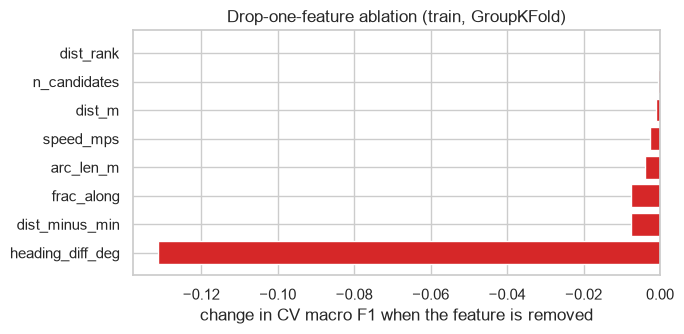

In [7]:
plt.figure(figsize=(7,3.5)); plt.barh(abl.dropped, abl.change_vs_all, color=['tab:red' if v < 0 else 'tab:green' for v in abl.change_vs_all])
plt.axvline(0, color='k', lw=0.8); plt.xlabel('change in CV macro F1 when the feature is removed'); plt.title('Drop-one-feature ablation (train, GroupKFold)')
plt.tight_layout(); plt.savefig(f'{FIG}/fs_ablation.png', dpi=110); plt.show()

## 6. Decision
**Findings:** heading_diff_deg is by far the most important feature (removing it drops CV macro F1 by ~0.13) — it is the only feature that separates the two directions of a two-way street. speed_mps has ~zero mutual information on its own but removing it still lowers F1: it is useful only in combination with heading (heading is unreliable at low speed). dist_rank is redundant: it carries the same ordering information as dist_minus_min, and removing it does not change the score (the only highly correlated pair is dist_m / dist_minus_min, rho 0.88, but both still help in the ablation); we keep it because it costs nothing and is intuitive, but it could be dropped.

Rule used: read the outputs above: a feature is kept if removing it lowers CV macro F1 (red bar) or it ranks high on permutation importance; a feature is a candidate for removal if removing it does not hurt and it is highly correlated with another. The conclusion printed below is computed from the ablation table, not typed.

In [8]:
keep = abl[abl.change_vs_all < -0.0005].dropped.tolist(); neutral = abl[abl.change_vs_all >= -0.0005].dropped.tolist()
print('Removing these HURTS CV F1 -> keep:', keep)
print('Removing these does not hurt (within 0.0005) -> neutral:', neutral)

Removing these HURTS CV F1 -> keep: ['heading_diff_deg', 'dist_minus_min', 'frac_along', 'arc_len_m', 'speed_mps', 'dist_m', 'n_candidates']
Removing these does not hurt (within 0.0005) -> neutral: ['dist_rank']
